In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import data_loader
import pandas as pd
import numpy as np
from pathlib import Path


importlib.reload(data_loader)

begin_inventory, end_inventory, purchase_prices, purchases, vendor_invoice = data_loader.load_data()

# Understand datasets


In [2]:
# checking all table are in progress

datasets = {
    'begin_inventory': begin_inventory,
    'end_inventory': end_inventory,
    'purchase_prices': purchase_prices,
    'purchases': purchases,
    'vendor_invoice': vendor_invoice
}

for name, df in datasets.items():
    print('-' * 50)
    print(name)
    print('Rows and Columns:', df.shape)
    print('Total Records:', len(df))

--------------------------------------------------
begin_inventory
Rows and Columns: (206529, 9)
Total Records: 206529
--------------------------------------------------
end_inventory
Rows and Columns: (224489, 9)
Total Records: 224489
--------------------------------------------------
purchase_prices
Rows and Columns: (12261, 9)
Total Records: 12261
--------------------------------------------------
purchases
Rows and Columns: (2372474, 16)
Total Records: 2372474
--------------------------------------------------
vendor_invoice
Rows and Columns: (5543, 10)
Total Records: 5543


In [3]:
# display table
for name, df in datasets.items():
    print("="*60)
    print("Information of dataset name -----> ",name)
    print(df.head())

Information of dataset name ----->  begin_inventory
         InventoryId  Store          City  Brand                  Description  \
0  1_HARDERSFIELD_58      1  HARDERSFIELD     58  Gekkeikan Black & Gold Sake   
1  1_HARDERSFIELD_60      1  HARDERSFIELD     60       Canadian Club 1858 VAP   
2  1_HARDERSFIELD_62      1  HARDERSFIELD     62     Herradura Silver Tequila   
3  1_HARDERSFIELD_63      1  HARDERSFIELD     63   Herradura Reposado Tequila   
4  1_HARDERSFIELD_72      1  HARDERSFIELD     72         No. 3 London Dry Gin   

    Size  onHand  Price   startDate  
0  750mL       8  12.99  2024-01-01  
1  750mL       7  10.99  2024-01-01  
2  750mL       6  36.99  2024-01-01  
3  750mL       3  38.99  2024-01-01  
4  750mL       6  34.99  2024-01-01  
Information of dataset name ----->  end_inventory
         InventoryId  Store          City  Brand                  Description  \
0  1_HARDERSFIELD_58      1  HARDERSFIELD     58  Gekkeikan Black & Gold Sake   
1  1_HARDERSFIELD_62 

In [4]:
# checking for null
for name, df in datasets.items():
    print("="*60)
    print("Information of dataset name -----> ",name)
    print(df.isnull().sum())

Information of dataset name ----->  begin_inventory
InventoryId    0
Store          0
City           0
Brand          0
Description    0
Size           0
onHand         0
Price          0
startDate      0
dtype: int64
Information of dataset name ----->  end_inventory
InventoryId       0
Store             0
City           1284
Brand             0
Description       0
Size              0
onHand            0
Price             0
endDate           0
dtype: int64
Information of dataset name ----->  purchase_prices
Brand             0
Description       1
Price             0
Size              1
Volume            1
Classification    0
PurchasePrice     0
VendorNumber      0
VendorName        0
dtype: int64
Information of dataset name ----->  purchases
InventoryId       0
Store             0
Brand             0
Description       0
Size              3
VendorNumber      0
VendorName        0
PONumber          0
PODate            0
ReceivingDate     0
InvoiceDate       0
PayDate           0
Purchase

In [5]:
# calculating numbe of null in percentage in end inventory
co = (1284/len(end_inventory)) * 100
co

0.5719656642419005

In [6]:
# droping null value as it is very less to contribute to data analysis
for name, df in datasets.items():
    if name == 'vendor_invoice':
        continue
    datasets[name] = df.dropna()

In [7]:
# asign no null value into table
# begin_inventory, end_inventory, purchase_prices, purchases, vendor_invoice
begin_inventory = datasets['begin_inventory']
end_inventory = datasets['end_inventory']
purchase_prices = datasets['purchase_prices']
purchases = datasets['purchases']
vendor_invoice = datasets['vendor_invoice']

In [8]:
# checking null value
for name, df in datasets.items():
    print("="*60)
    print("Information of dataset name -----> ",name)
    print(df.isnull().sum())

Information of dataset name ----->  begin_inventory
InventoryId    0
Store          0
City           0
Brand          0
Description    0
Size           0
onHand         0
Price          0
startDate      0
dtype: int64
Information of dataset name ----->  end_inventory
InventoryId    0
Store          0
City           0
Brand          0
Description    0
Size           0
onHand         0
Price          0
endDate        0
dtype: int64
Information of dataset name ----->  purchase_prices
Brand             0
Description       0
Price             0
Size              0
Volume            0
Classification    0
PurchasePrice     0
VendorNumber      0
VendorName        0
dtype: int64
Information of dataset name ----->  purchases
InventoryId       0
Store             0
Brand             0
Description       0
Size              0
VendorNumber      0
VendorName        0
PONumber          0
PODate            0
ReceivingDate     0
InvoiceDate       0
PayDate           0
PurchasePrice     0
Quantity       

In [9]:
# Duplicate data finding
for name, df in datasets.items():

    print(f"\n{'='*40}")
    print(name)
    print('='*40)

    print("Total Records:", len(df))
    print("Duplicate Records:", df.duplicated().sum())
print("Over")    


begin_inventory
Total Records: 206529
Duplicate Records: 0

end_inventory
Total Records: 223205
Duplicate Records: 0

purchase_prices
Total Records: 12260
Duplicate Records: 0

purchases
Total Records: 2372471
Duplicate Records: 0

vendor_invoice
Total Records: 5543
Duplicate Records: 0
Over


In [10]:
# understand the data set 
for name, df in datasets.items():
    print("="*60)
    print("Information of dataset name -----> ",name)
    print(df.info())
    

Information of dataset name ----->  begin_inventory
<class 'pandas.DataFrame'>
RangeIndex: 206529 entries, 0 to 206528
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InventoryId  206529 non-null  str    
 1   Store        206529 non-null  int64  
 2   City         206529 non-null  str    
 3   Brand        206529 non-null  int64  
 4   Description  206529 non-null  str    
 5   Size         206529 non-null  str    
 6   onHand       206529 non-null  int64  
 7   Price        206529 non-null  float64
 8   startDate    206529 non-null  str    
dtypes: float64(1), int64(3), str(5)
memory usage: 14.2 MB
None
Information of dataset name ----->  end_inventory
<class 'pandas.DataFrame'>
Index: 223205 entries, 0 to 224488
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InventoryId  223205 non-null  str    
 1   Store        223205 non-null  int6

In [11]:
# converting data type of purchases datetime
date_columns = ['PODate', 'ReceivingDate', 'InvoiceDate', 'PayDate']

for col in date_columns:
    purchases[col] = pd.to_datetime(purchases[col], errors='coerce')

In [12]:
# converting data type of vendor_invoice datetime
date_columns = ['PODate','PayDate','InvoiceDate']

for col in date_columns:
    vendor_invoice[col] = pd.to_datetime(vendor_invoice[col], errors='coerce')

In [13]:
# converting data type of begin_inventory, end_inventory, purchase_prices datetime

begin_inventory['startDate'] = pd.to_datetime(begin_inventory['startDate'], errors = 'coerce')
end_inventory['endDate'] = pd.to_datetime(end_inventory['endDate'], errors = 'coerce')

In [14]:
for name, df in datasets.items():
    print("="*60)
    print("Information of dataset name -----> ",name)
    print(df.info())

Information of dataset name ----->  begin_inventory
<class 'pandas.DataFrame'>
RangeIndex: 206529 entries, 0 to 206528
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InventoryId  206529 non-null  str           
 1   Store        206529 non-null  int64         
 2   City         206529 non-null  str           
 3   Brand        206529 non-null  int64         
 4   Description  206529 non-null  str           
 5   Size         206529 non-null  str           
 6   onHand       206529 non-null  int64         
 7   Price        206529 non-null  float64       
 8   startDate    206529 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(3), str(4)
memory usage: 14.2 MB
None
Information of dataset name ----->  end_inventory
<class 'pandas.DataFrame'>
Index: 223205 entries, 0 to 224488
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       ----

In [15]:
# vendor_invoice 
vendor_invoice['Approval'].value_counts(dropna=False)

Approval
NaN               5169
Frank Delahunt     374
Name: count, dtype: int64

In [16]:
purchase_prices['Volume'].value_counts().head(20)

Volume
750        9840
1500        497
1750        433
1000        428
375         323
50          292
3000        104
187         104
500          51
5000         44
200          34
300          24
4000         16
720          11
100          10
250           9
330           5
180           5
20000         5
Unknown       4
Name: count, dtype: int64

In [17]:
# convert volumn to int value
purchase_prices['Volume'] = pd.to_numeric(
    purchase_prices['Volume'].replace('Unknown', pd.NA),
    errors = 'coerce'
).astype('float64')

In [18]:
print(purchase_prices['Volume'].dtype)
print(purchase_prices['Volume'].unique())

float64
[  750.   1000.   1750.     50.    375.    100.    200.    300.      nan
   250.   1500.   3000.   5000.   4000.    187.    150.    500.    720.
   650.    330.  18000.    180.   6000.     20.  20000.    162.5   400.
  1100.    600.  19500.    560.   3750.   9000. ]


In [19]:
# Descriptive analyse
for name, df in datasets.items():
    print("\n", "="*50)
    print(name)
    print("="*50)

    print(df.describe())


begin_inventory
               Store          Brand         onHand          Price  \
count  206529.000000  206529.000000  206529.000000  206529.000000   
mean       42.122457   13761.482320      20.429455      22.253910   
min         1.000000      58.000000       0.000000       0.000000   
25%        22.000000    3746.000000       7.000000       9.990000   
50%        42.000000    8010.000000      12.000000      14.990000   
75%        64.000000   22143.000000      21.000000      21.990000   
max        79.000000   90090.000000    1251.000000   13999.900000   
std        23.191393   13059.429355      31.467342      70.178964   

                 startDate  
count               206529  
mean   2024-01-01 00:00:00  
min    2024-01-01 00:00:00  
25%    2024-01-01 00:00:00  
50%    2024-01-01 00:00:00  
75%    2024-01-01 00:00:00  
max    2024-01-01 00:00:00  
std                    NaN  

end_inventory
               Store          Brand         onHand          Price  \
count  223205.00

# purchases table

# Dollars

In [20]:
# checking purchases
purchases['Dollars'].describe()

count    2.372471e+06
mean     1.356816e+02
std      2.816651e+02
min      0.000000e+00
25%      4.926000e+01
50%      8.393000e+01
75%      1.405200e+02
max      5.017570e+04
Name: Dollars, dtype: float64

# 1. What can we conclude?
**Finding 1**: Right-skewed distribution

Your mean (135.68) is considerably higher than your median (83.93).

This suggests that a relatively small number of large purchases are pulling the average upward.

**Finding 2**: High variation

Standard deviation (281.67) is greater than the mean. Purchase amounts vary considerably.

**Finding 3**: Potential outliers

The maximum is 50,175.70, while 75% of purchases are at or below 140.52. This is a strong reason to investigate extreme values.

**Finding 4**: Zero purchase amounts

The minimum is zero. We should investigate these records to understand why they have no recorded purchase amount.

# Insight of Dollar purchases
- Count	----> 2,372,471	Dollar
- Mean	---->  135.68 Dollar	
- Std	----> 281.67	Dollar  High variation in purchase amounts
- Minimum	---->  0	Dollar
- 25% (Q1)	---->  49.26	Dollar
- 50% (Median)	---->  83.93	Dollar
- 75% (Q3)	---->  140.52	Dollar
- Maximum	----> 50,175.70	Dollar

# Analyze distributions and outliers

# Histogram
**Histogram** plot for purchase

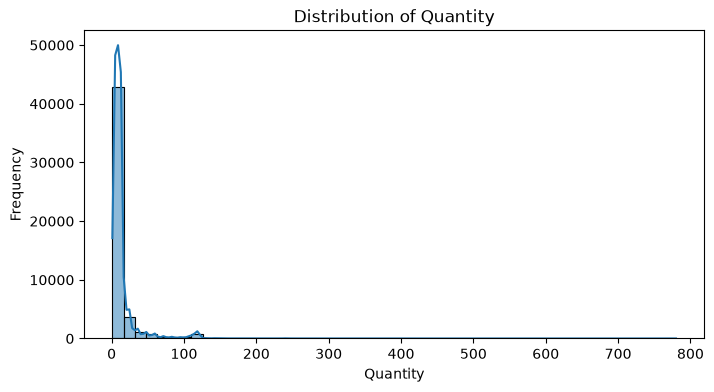

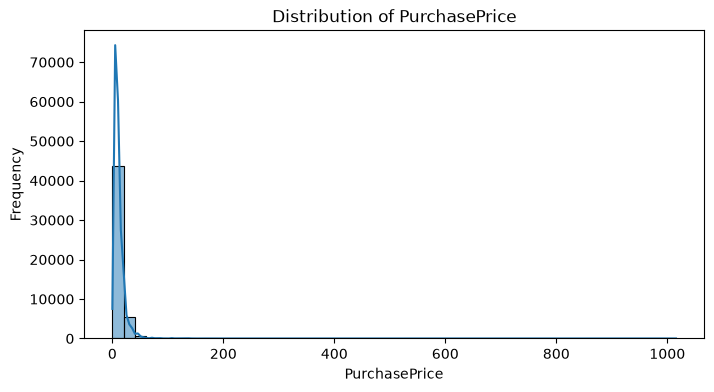

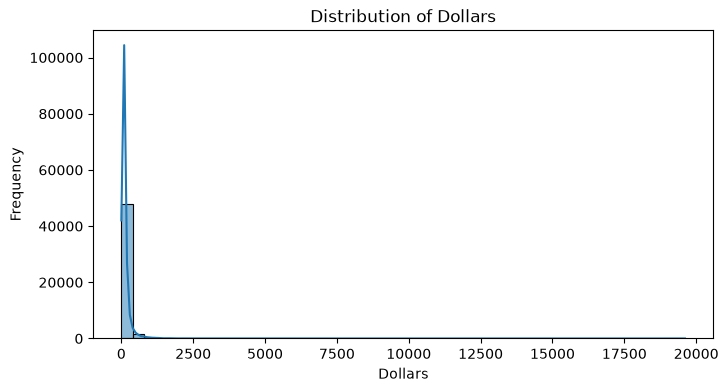

In [21]:
# checking for outlier in purchases 
columns = ['Quantity', 'PurchasePrice', 'Dollars']
for col in columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=purchases.sample(50000, random_state=42),
                 x=col, bins=50, kde=True)
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(f'{col}')
    plt.ylabel('Frequency')
    plt.show()

# 2. Calculate the outlier limits for Dollars

In [22]:
Q1 = purchases['Dollars'].quantile(0.25)
Q3 = purchases['Dollars'].quantile(0.75)

IQR = Q3-Q1

lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

print("IQR: ", IQR)
print("lower limit", lower_limit, "upper limit: ", upper_limit)

IQR:  91.26000000000002
lower limit -87.63000000000005 upper limit:  277.4100000000001


In [23]:
purchases.nlargest(10, 'Dollars')[
    ['VendorName', 'Brand', 'Quantity', 'PurchasePrice', 'Dollars']
]

,VendorName,Brand,Quantity,PurchasePrice,Dollars
1404805,BROWN-FORMAN CORP,1233,1910,26.27,50175.70
1661600,JIM BEAM BRANDS COMPANY,1376,2425,16.29,39503.25
1973759,DIAGEO NORTH AMERICA INC,2753,870,44.77,38949.90
1194496,BACARDI USA INC,3858,2055,17.77,36517.35
1920491,BACARDI USA INC,126,1763,20.14,35506.82
1963950,BACARDI USA INC,126,1612,20.14,32465.68
1947552,MOET HENNESSY USA INC,42188,954,34.01,32445.54
1843836,DIAGEO NORTH AMERICA INC,2753,703,44.77,31473.31
1966318,BROWN-FORMAN CORP,1233,1164,26.27,30578.28
1759909,JIM BEAM BRANDS COMPANY,2277,1793,17.03,30534.79


# Insight 
1. lower limit -87.63000000000005
2. upper limit:  277.4100000000001
3. IQR:  91.26000000000002
- we can say from Dollars columns that Purchase amounts exhibit a positively skewed distribution. The average purchase amount is higher than the median, indicating that large transactions influence overall spending. Extreme purchase amounts require further investigation to identify high-value procurement transactions.

In [24]:
outliers = purchases[purchases['Dollars'] > upper_limit]

print('Total number: ', len(purchases))
print('Outliers number: ', len(outliers))

print('Outliers percentage: ', round((len(outliers)/len(purchases))*100 ,2))

Total number:  2372471
Outliers number:  191797
Outliers percentage:  8.08


# One more important check: zero purchase amounts

In [25]:
print('zero purchase amounts: ', (purchases['Dollars'] == 0).sum())

zero purchase amounts:  153


# What to write in your EDA notebook
You can record these findings:
- Purchase amount distribution is positively skewed.
- Average purchase amount is higher than the median.
- IQR upper outlier threshold is $277.41.
- Several high-value procurement transactions were identified.
- High-value transactions should be investigated rather than automatically removed.

# What does this mean?
- 8.08% potential outliers: Approximately 8 out of every 100 transactions exceed the IQR upper limit of $277.41.
- 153 zero-dollar transactions: These records need investigation to understand why their recorded purchase amount is zero.
- 191,797 outliers: This is a substantial number, but it doesn't mean these transactions are incorrect.

# Quantity

In [26]:
purchases['Quantity'].describe()

count    2.372471e+06
mean     1.415586e+01
std      2.344617e+01
min      1.000000e+00
25%      6.000000e+00
50%      1.000000e+01
75%      1.200000e+01
max      3.816000e+03
Name: Quantity, dtype: float64

In [27]:
# Calculate IQR limits.
Q1 = purchases['Quantity'].quantile(0.25)
Q3 = purchases['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

print("IQR: ", IQR)
print("lower limit ",lower_limit, " upper limit ", upper_limit)

IQR:  6.0
lower limit  -3.0  upper limit  21.0


In [28]:
# calculating outliers
outliers1 = purchases[
    purchases['Quantity'] > upper_limit
]

print('Totals number: ', len(purchases))
print('outliers number: ', len(outliers1))
print('Percentage of outliers: ', round((len(outliers1)/len(purchases))*100, 2))

Totals number:  2372471
outliers number:  284431
Percentage of outliers:  11.99


In [29]:
# printing largest Quantity
purchases.nlargest(10, 'Quantity')[
    ['VendorName', 'Brand', 'Quantity', 'PurchasePrice', 'Dollars']
]

,VendorName,Brand,Quantity,PurchasePrice,Dollars
2130897,M S WALKER INC,5609,3816,4.68,17858.88
1661600,JIM BEAM BRANDS COMPANY,1376,2425,16.29,39503.25
1194992,BACARDI USA INC,4246,2159,4.22,9110.98
1194496,BACARDI USA INC,3858,2055,17.77,36517.35
2130168,M S WALKER INC,5614,1920,3.99,7660.80
1404805,BROWN-FORMAN CORP,1233,1910,26.27,50175.70
2131948,M S WALKER INC,5598,1896,3.99,7565.04
1595345,"STOLI GROUP,(USA) LLC",8500,1800,6.28,11304.00
1595528,"STOLI GROUP,(USA) LLC",754,1800,7.40,13320.00
1759909,JIM BEAM BRANDS COMPANY,2277,1793,17.03,30534.79


In [30]:
# checking of negative Quantity 
print("Number of negative quantity ", (purchases['Quantity'] <= 0).sum()) 

Number of negative quantity  0


# EDA notebook:
Purchase quantity analysis identified 284,431 potential outliers, representing 11.99% of total transactions.
The IQR upper limit was 21 units. 
Several transactions contain unusually large quantities, indicating bulk procurement activities. 
These transactions should be retained unless further investigation identifies data errors.

# PurchasePrice

In [31]:
# decsribe
purchases['PurchasePrice'].describe()

count    2.372471e+06
mean     1.205002e+01
std      1.794504e+01
min      0.000000e+00
25%      6.120000e+00
50%      9.220000e+00
75%      1.449000e+01
max      5.681810e+03
Name: PurchasePrice, dtype: float64

In [32]:
Q1 = purchases['PurchasePrice'].quantile(0.25)
Q3 = purchases['PurchasePrice'].quantile(0.75)

IQR = Q3-Q1

lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

print('IQR: ', IQR)
print('lower limit ',lower_limit , 'upper limit ', upper_limit)

IQR:  8.370000000000001
lower limit  -6.435000000000001 upper limit  27.045


In [33]:
# outlier count
outliers_price = purchases[
    (purchases['PurchasePrice'] < lower_limit) | (purchases['PurchasePrice'] > upper_limit)
]
print("Outliers:", len(outliers_price))

print(
    "Outlier percentage:",
    round(len(outliers_price) / len(purchases) * 100, 2)
)

Outliers: 137316
Outlier percentage: 5.79


In [34]:
# checking for largest value
purchases.nlargest(10, 'PurchasePrice')[
    ['VendorName', 'Brand', 'Quantity', 'PurchasePrice', 'Dollars']
]

,VendorName,Brand,Quantity,PurchasePrice,Dollars
113043,ULTRA BEVERAGE COMPANY LLP,3949,1,5681.81,5681.81
113227,ULTRA BEVERAGE COMPANY LLP,3949,1,5681.81,5681.81
113455,ULTRA BEVERAGE COMPANY LLP,3949,1,5681.81,5681.81
185547,MOET HENNESSY USA INC,2367,1,4264.70,4264.70
1433768,MOET HENNESSY USA INC,2367,1,4264.70,4264.70
966295,MOET HENNESSY USA INC,423,1,3352.93,3352.93
1433535,MOET HENNESSY USA INC,423,1,3352.93,3352.93
1719606,MOET HENNESSY USA INC,423,1,3352.93,3352.93
1452024,WILLIAM GRANT & SONS INC,8385,1,2713.17,2713.17
749766,DIAGEO NORTH AMERICA INC,1251,1,2661.86,2661.86


In [35]:
# checking for price 
print("Zero prices:",
      (purchases['PurchasePrice'] == 0).sum())

print("Negative prices:",
      (purchases['PurchasePrice'] < 0).sum())

Zero prices: 153
Negative prices: 0


# EDA for purchases_price
PurchasePrice analysis identified 137,316 potential outliers (5.79%) using the IQR method, with an upper threshold of $27.045. These observations may represent high-value products and require further investigation before being classified as errors or removed. there is zero prices of 153

# Vendor Invoice Table analysis

# Freight

In [36]:
vendor_invoice['Freight'].describe()

count    5543.000000
mean      295.954301
std       713.585093
min         0.020000
25%         5.020000
50%        24.730000
75%       229.660000
max      8468.220000
Name: Freight, dtype: float64

In [37]:
Q1 = vendor_invoice['Freight'].quantile(0.25)
Q3 = vendor_invoice['Freight'].quantile(0.75)

IQR = Q3-Q1

lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

print('IQR: ', IQR)
print('lower limit: ', lower_limit, ' upper limit: ', upper_limit)

IQR:  224.64
lower limit:  -331.94  upper limit:  566.62


In [38]:
# Count outliers
outliers_freight = vendor_invoice[
   ( vendor_invoice['Freight'] > upper_limit ) |
    (vendor_invoice['Freight'] < lower_limit)
]

print("Outliers: ", len(outliers_freight))
print("Total freight: ", len(vendor_invoice))
print("Outlier percentage: ", round(len(outliers_freight) / len(vendor_invoice) * 100, 2))

Outliers:  738
Total freight:  5543
Outlier percentage:  13.31


In [39]:
vendor_invoice.nlargest(10, 'Freight')[
    ['VendorName', 'VendorNumber', 'Quantity', 'Dollars', 'Freight']
]

,VendorName,VendorNumber,Quantity,Dollars,Freight
4728,DIAGEO NORTH AMERICA INC,3960,141660,1660435.88,8468.22
4627,DIAGEO NORTH AMERICA INC,3960,127553,1409683.51,7753.26
2822,DIAGEO NORTH AMERICA INC,3960,131712,1377224.55,7574.74
4521,DIAGEO NORTH AMERICA INC,3960,122740,1468470.64,7048.66
3025,DIAGEO NORTH AMERICA INC,3960,128861,1354087.31,7041.25
4829,DIAGEO NORTH AMERICA INC,3960,119586,1321953.42,7006.35
2125,DIAGEO NORTH AMERICA INC,3960,117416,1219948.49,6709.72
3129,DIAGEO NORTH AMERICA INC,3960,114609,1225680.18,6373.54
5037,DIAGEO NORTH AMERICA INC,3960,116491,1319062.86,6331.50
2924,DIAGEO NORTH AMERICA INC,3960,131032,1160975.84,6269.27


# EDA 
Freight cost analysis identified 738 potential outliers (13.31%) using the IQR method. The upper outlier threshold was $566.62. This indicates substantial variation in transportation costs across vendor invoices. Further investigation is required to identify vendors and shipments associated with unusually high freight charges.

In [40]:
# Calculate freight percentage
vendor_invoice['Freight_percentage'] = (vendor_invoice['Freight'] / vendor_invoice['Dollars'])*100

vendor_invoice.nlargest(10, 'Freight_percentage')[
    ['VendorName', 'Quantity', 'Dollars',
     'Freight', 'Freight_percentage']
]

,VendorName,Quantity,Dollars,Freight,Freight_percentage
36,LAIRD & CO,12,120.72,13.91,11.522531
88,ZORVINO VINEYARDS,23,186.93,21.04,11.255550
8,CALEDONIA SPIRITS INC,5,146.80,15.53,10.579019
33,KLIN SPIRITS LLC,7,98.49,9.65,9.797949
58,PSP WINES,11,66.33,6.09,9.181366
75,TALL SHIP DISTILLERY LLC,6,133.26,10.59,7.946871
56,PREMIER DISTRIBUTORS,11,176.11,12.08,6.859349
74,TAKARA SAKE USA INC,12,55.08,3.62,6.572259
1,AMERICAN VINTAGE BEVERAGE,15,140.55,8.57,6.097474
42,MARTIGNETTI COMPANIES,24,193.80,11.38,5.872033


# Record of current EDA finding
You can write:
The top 10 highest freight invoices were all associated with DIAGEO NORTH AMERICA INC (VendorNumber 3960). These invoices also contained very large purchase quantities and invoice values. Further analysis of freight as a percentage of invoice value is required before determining whether the vendor has unusually high transportation costs.

# Business insight
Although DIAGEO NORTH AMERICA INC accounts for the highest individual freight charges, its invoices are also associated with very large purchase values. When freight is evaluated as a percentage of invoice value, LAIRD & CO has the highest observed ratio at approximately 11.52%. This indicates that absolute freight cost alone may not provide a fair comparison of vendor transportation efficiency.

# Analyze invoice Dollars

In [41]:
vendor_invoice['Dollars'].describe()

count    5.543000e+03
mean     5.807338e+04
std      1.402340e+05
min      4.140000e+00
25%      9.678100e+02
50%      4.765450e+03
75%      4.458718e+04
max      1.660436e+06
Name: Dollars, dtype: float64

In [42]:
Q1 = vendor_invoice['Dollars'].quantile(0.25)
Q3 = vendor_invoice['Dollars'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

IQR: 43619.365000000005
Lower limit: -64461.23750000001
Upper limit: 110016.2225


In [43]:
outliers_invoice = vendor_invoice[
    (vendor_invoice['Dollars'] < lower_limit) | (vendor_invoice['Dollars'] > upper_limit)
]

print("Total invoices:", len(vendor_invoice))
print("Potential outliers:", len(outliers_invoice))

print(
    "Outlier percentage:",
    round(len(outliers_invoice) / len(vendor_invoice) * 100, 2)
)

Total invoices: 5543
Potential outliers: 748
Outlier percentage: 13.49


In [44]:
vendor_invoice.nlargest(10, 'Dollars')[
    ['VendorName', 'VendorNumber', 'Quantity', 'Dollars', 'Freight']
]

,VendorName,VendorNumber,Quantity,Dollars,Freight
4728,DIAGEO NORTH AMERICA INC,3960,141660,1660435.88,8468.22
4521,DIAGEO NORTH AMERICA INC,3960,122740,1468470.64,7048.66
4627,DIAGEO NORTH AMERICA INC,3960,127553,1409683.51,7753.26
2822,DIAGEO NORTH AMERICA INC,3960,131712,1377224.55,7574.74
3025,DIAGEO NORTH AMERICA INC,3960,128861,1354087.31,7041.25
4829,DIAGEO NORTH AMERICA INC,3960,119586,1321953.42,7006.35
5037,DIAGEO NORTH AMERICA INC,3960,116491,1319062.86,6331.50
5456,DIAGEO NORTH AMERICA INC,3960,129816,1226463.19,6132.32
3129,DIAGEO NORTH AMERICA INC,3960,114609,1225680.18,6373.54
2125,DIAGEO NORTH AMERICA INC,3960,117416,1219948.49,6709.72


# EDA 
The top 10 highest-value invoices were all associated with DIAGEO NORTH AMERICA INC (VendorNumber 3960).Vendor invoice amount analysis identified 748 potential outliers, representing 13.49% of all invoices. The IQR upper threshold was $110,016.22. These high-value invoices may represent bulk procurement transactions and require further investigation to understand vendor spending concentration.

# Analyze invoice Quantity

In [45]:
vendor_invoice['Quantity'].describe()

count      5543.000000
mean       6058.880931
std       14453.338164
min           1.000000
25%          83.000000
50%         423.000000
75%        5100.500000
max      141660.000000
Name: Quantity, dtype: float64

In [46]:
Q1 = vendor_invoice['Quantity'].quantile(0.25)
Q3 = vendor_invoice['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

IQR: 5017.5
Lower limit: -7443.25
Upper limit: 12626.75


In [47]:
outliers = vendor_invoice[
    (vendor_invoice['Quantity'] < lower_limit) |
    (vendor_invoice['Quantity'] > upper_limit)
]

print("Number of outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(vendor_invoice) * 100, 2), "%")

Number of outliers: 701
Outlier percentage: 12.65 %


In [48]:
vendor_invoice.nlargest(10, 'Quantity')[
    ['VendorName', 'VendorNumber', 'Quantity', 'Dollars', 'Freight']
]

,VendorName,VendorNumber,Quantity,Dollars,Freight
4728,DIAGEO NORTH AMERICA INC,3960,141660,1660435.88,8468.22
5240,DIAGEO NORTH AMERICA INC,3960,134333,1127733.09,5300.35
2822,DIAGEO NORTH AMERICA INC,3960,131712,1377224.55,7574.74
2924,DIAGEO NORTH AMERICA INC,3960,131032,1160975.84,6269.27
5456,DIAGEO NORTH AMERICA INC,3960,129816,1226463.19,6132.32
3025,DIAGEO NORTH AMERICA INC,3960,128861,1354087.31,7041.25
4627,DIAGEO NORTH AMERICA INC,3960,127553,1409683.51,7753.26
5349,DIAGEO NORTH AMERICA INC,3960,124996,1104187.97,4968.85
4521,DIAGEO NORTH AMERICA INC,3960,122740,1468470.64,7048.66
3428,DIAGEO NORTH AMERICA INC,3960,119801,1104864.79,5855.78


# EDA 
DIAGEO NORTH AMERICA INC has some exceptionally large purchase invoices. These transactions contribute to the high-quantity outliers in the dataset.
Number of outliers: 701, Outlier percentage: 12.65 %. having number of record 5543.000000, with Average (mean) 6058.880931 Dollar, std  14453.338164 Dollar. Highly right-skewed distribution
Mean 6,058.88 Dollar is much higher than median(50%) 423 Dollar.

# purchase_prices table

# Price

In [49]:
purchase_prices['Price'].describe()

count    12260.000000
mean        38.643392
std        206.159284
min          0.000000
25%         10.990000
50%         15.990000
75%         29.990000
max      13999.900000
Name: Price, dtype: float64

In [50]:
Q1 = purchase_prices['Price'].quantile(0.25)
Q3 = purchase_prices['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

IQR: 19.0
Lower limit: -17.509999999999998
Upper limit: 58.489999999999995


In [51]:
outliers_purchase_prices = purchase_prices[
    (purchase_prices['Price'] > upper_limit) | (purchase_prices['Price'] < lower_limit) 
]

print("Total invoices:", len(purchase_prices))
print("Potential outliers:", len(outliers_purchase_prices))

print(
    "Outlier percentage:",
    round(len(outliers_purchase_prices) / len(purchase_prices) * 100, 2)
)

Total invoices: 12260
Potential outliers: 1275
Outlier percentage: 10.4


In [52]:
purchase_prices.nlargest(10, 'Price')[
    ['Brand', 'Description', 'Size', 'Price', 'PurchasePrice', 'VendorName']
]

,Brand,Description,Size,Price,PurchasePrice,VendorName
9162,2693,Glen Grant 50 Yr Scotch,750mL,13999.90,11111.03,CAMPARI AMERICA
9671,3949,Patron En Lalique Tequila,750mL,7499.99,5681.81,ULTRA BEVERAGE COMPANY LLP
7428,2367,Glenmorangie Pride,1000mL,5799.99,4264.70,MOET HENNESSY USA INC
7427,1991,The Macallan M Decanter,750mL,4999.99,3787.87,EDRINGTON AMERICAS
9211,4423,Appleton Estate 50Yr Old Rum,750mL,4999.99,3649.63,CAMPARI AMERICA
5798,423,Hennessy Richard Cognac,750mL,4559.99,3352.93,MOET HENNESSY USA INC
6061,16191,Armand De Brignac Brut,6000mL,4222.99,2816.43,ULTRA BEVERAGE COMPANY LLP
7430,2996,Highland Park 1968,750mL,3999.99,3149.60,EDRINGTON AMERICAS
10402,1251,Port Ellen 32 Yr Single Malt,750mL,3699.99,2661.86,DIAGEO NORTH AMERICA INC
9441,8385,Glenfiddich 1978 Rare Collct,750mL,3499.99,2713.17,WILLIAM GRANT & SONS INC


In [53]:
# Check zero-price records
zero_purchase = purchase_prices[purchase_prices['Price'] == 0]
print('Zero purchases record: ', len(zero_purchase))
zero_purchase[
    ['Brand', 'Description', 'Size', 'Price', 'PurchasePrice', 'VendorName']
].head(10)

Zero purchases record:  1


,Brand,Description,Size,Price,PurchasePrice,VendorName
10803,2166,The Macallan Double Cask 12,750mL,0.0,0.0,EDRINGTON AMERICAS


# EDA 
While investigating we can say that there is one record of zero Price & PurchasePrice whose vendor name is EDRINGTON AMERICAS.
number of record 12260.000000, average price is 38.643392, min price is 0.000000, median(50%) is  15.990000, max price is 13999.900000.
Record is right sekwed as avg reord is more then median which state that record is highly influenced by maximum price. Total invoices: 12260
Potential outliers: 1275
Outlier percentage: 10.4

# PurchasePrice

In [54]:
purchase_prices['PurchasePrice'].describe()

count    12260.000000
mean        26.489467
std        156.189257
min          0.000000
25%          6.890000
50%         10.645000
75%         20.130000
max      11111.030000
Name: PurchasePrice, dtype: float64

In [55]:
Q1 = purchase_prices['PurchasePrice'].quantile(0.25)
Q3 = purchase_prices['PurchasePrice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

IQR: 13.239999999999998
Lower limit: -12.969999999999999
Upper limit: 39.989999999999995


In [56]:
outliers_PurchasePrice = purchase_prices[
    (purchase_prices['PurchasePrice'] < lower_limit) | (purchase_prices['PurchasePrice'] > upper_limit)

]

print('Number of outliers: ', len(outliers_PurchasePrice))
print('number of total records: ', len(purchase_prices))
print('percentage of outliers:', round((len(outliers_PurchasePrice)/len(purchase_prices)) * 100, 2))

Number of outliers:  1241
number of total records:  12260
percentage of outliers: 10.12


In [57]:
purchase_prices.nlargest(10, 'PurchasePrice')[
    ['Brand', 'Description', 'Size', 'Price', 'PurchasePrice', 'VendorName']
]

,Brand,Description,Size,Price,PurchasePrice,VendorName
9162,2693,Glen Grant 50 Yr Scotch,750mL,13999.90,11111.03,CAMPARI AMERICA
9671,3949,Patron En Lalique Tequila,750mL,7499.99,5681.81,ULTRA BEVERAGE COMPANY LLP
7428,2367,Glenmorangie Pride,1000mL,5799.99,4264.70,MOET HENNESSY USA INC
7427,1991,The Macallan M Decanter,750mL,4999.99,3787.87,EDRINGTON AMERICAS
9211,4423,Appleton Estate 50Yr Old Rum,750mL,4999.99,3649.63,CAMPARI AMERICA
5798,423,Hennessy Richard Cognac,750mL,4559.99,3352.93,MOET HENNESSY USA INC
7430,2996,Highland Park 1968,750mL,3999.99,3149.60,EDRINGTON AMERICAS
6061,16191,Armand De Brignac Brut,6000mL,4222.99,2816.43,ULTRA BEVERAGE COMPANY LLP
9441,8385,Glenfiddich 1978 Rare Collct,750mL,3499.99,2713.17,WILLIAM GRANT & SONS INC
10402,1251,Port Ellen 32 Yr Single Malt,750mL,3699.99,2661.86,DIAGEO NORTH AMERICA INC


In [58]:
zero_purchase = purchase_prices[purchase_prices['PurchasePrice'] == 0]
print('Zero purchases record: ', len(zero_purchase))
zero_purchase[
    ['Brand', 'Description', 'Size', 'Price', 'PurchasePrice', 'VendorName']
].head(10)

Zero purchases record:  1


,Brand,Description,Size,Price,PurchasePrice,VendorName
10803,2166,The Macallan Double Cask 12,750mL,0.0,0.0,EDRINGTON AMERICAS


# EDA
Mean (26.49) is considerably higher than median (10.645), suggesting a right-skewed distribution.
The maximum purchase price is unusually high.
Purchase prices vary substantially across products.
We already identified one record where both Price and PurchasePrice are zero.
Number of outliers:  1241,
number of total records:  12260,
percentage of outliers: 10.12, Zero purchases record:  1 which will be miss match or error

# Volume

In [59]:
purchase_prices['Volume'].describe()

count    12256.000000
mean       842.921467
std        679.529628
min         20.000000
25%        750.000000
50%        750.000000
75%        750.000000
max      20000.000000
Name: Volume, dtype: float64

In [60]:
Q1 = purchase_prices['Volume'].quantile(0.25)
Q3 = purchase_prices['Volume'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 750.0
Q3: 750.0
IQR: 0.0
Lower limit: 750.0
Upper limit: 750.0


In [61]:
# Check the volume distribution
purchase_prices['Volume'].value_counts().head(10)

Volume
750.0     9840
1500.0     497
1750.0     433
1000.0     428
375.0      323
50.0       292
3000.0     104
187.0      104
500.0       51
5000.0      44
Name: count, dtype: int64

In [62]:
purchase_prices.nlargest(10, 'Volume')[
    ['Brand', 'Description', 'Size', 'Volume',
     'Price', 'PurchasePrice', 'VendorName']
]

,Brand,Description,Size,Volume,Price,PurchasePrice,VendorName
8798,23047,From the Tank Red Keg,20000mL,20000.0,230.49,149.67,VINILANDIA USA
9406,25463,Eden Dry Cider Keg,20000mL,20000.0,227.99,155.10,CRUSH WINES
10508,23491,True Myth Chard Keg,20000mL,20000.0,346.99,204.60,CRUSH WINES
11400,25464,Eden Rose Cider Keg,20000mL,20000.0,251.49,163.31,CRUSH WINES
12018,26146,Montelvini CabMerlot,20000mL,20000.0,221.99,151.01,FORTUNE WINE BROKERS LLC
11260,22565,Clayhouse Cab Svgn,19500mL,19500.0,183.99,118.70,MARTIGNETTI COMPANIES
4206,20650,Sho Chiku Bai Takara Sake,18000mL,18000.0,83.49,56.03,TAKARA SAKE USA INC
5633,29427,Gekkeikan Sake Calif,18000mL,18000.0,66.99,45.26,SHAW ROSS INT L IMP LTD
8564,24144,Ozeki Junmai Reishu Sake,18000mL,18000.0,72.49,49.31,PERFECTA WINES
12012,25457,GH Mumm Cordon Rouge,9000mL,9000.0,472.49,308.82,PERNOD RICARD USA


# EDA
The Volume column has a highly concentrated distribution, with 750 mL products dominating. Large-format keg products explain some of the extreme values. They should not automatically be removed.

# begin_inventory table

# onHand

In [63]:
begin_inventory['onHand'].describe()

count    206529.000000
mean         20.429455
std          31.467342
min           0.000000
25%           7.000000
50%          12.000000
75%          21.000000
max        1251.000000
Name: onHand, dtype: float64

In [64]:
Q1 = begin_inventory['onHand'].quantile(0.25)
Q3 = begin_inventory['onHand'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 7.0
Q3: 21.0
IQR: 14.0
Lower limit: -14.0
Upper limit: 42.0


In [65]:
outliers_onHand = begin_inventory[
    (begin_inventory['onHand'] < lower_limit) | (begin_inventory['onHand'] > upper_limit)
]
print('Outliers: ', len(outliers_onHand))
print('Percentage of Outliers: ', round(
    (len(outliers_onHand) / len(begin_inventory))*100 ,2
))


Outliers:  21171
Percentage of Outliers:  10.25


In [66]:
begin_inventory.nlargest(10, 'onHand')[
    ['Store', 'City', 'Brand', 'Description',
     'Size', 'onHand', 'Price']
]

,Store,City,Brand,Description,Size,onHand,Price
173397,69,MOUNTMEND,3858,Grey Goose Vodka,750mL,1251,23.99
204102,79,BALLYMENA,3859,Smirnoff 80 Proof,375mL,1163,8.99
79437,34,PITMERDEN,3876,Smirnoff 80 Proof,1.75L,930,17.99
157944,65,LUTON,7341,Smirnoff Watermelon,50mL,921,0.99
78556,34,PITMERDEN,1233,Jack Daniels No 7 Black,1.75L,888,35.99
80298,34,PITMERDEN,8068,Absolut 80 Proof,1.75L,865,24.99
119474,50,MOUNTMEND,4261,Capt Morgan Spiced Rum,1.75L,848,21.99
79432,34,PITMERDEN,3858,Grey Goose Vodka,750mL,818,23.99
196395,76,DONCASTER,8068,Absolut 80 Proof,1.75L,789,24.99
164412,67,EANVERNESS,3545,Ketel One Vodka,1.75L,743,31.99


In [67]:
zero_inventory = begin_inventory[
    begin_inventory['onHand'] == 0
]

print("Zero inventory records:", len(zero_inventory))
print(
    "Percentage:",
    round(len(zero_inventory) / len(begin_inventory) * 100, 2), "%"
)

Zero inventory records: 6044
Percentage: 2.93 %


# EDA
Some store-product combinations have significantly higher opening inventory than the typical level. These stores may need closer inventory monitoring to avoid overstocking, but we cannot conclude that they have excess stock without sales or demand data. A small portion of store-product combinations started the year with no inventory.

# end_inventory table

# onHand

In [68]:
end_inventory['onHand'].describe()

count    223205.000000
mean         21.889187
std          37.303803
min           0.000000
25%           7.000000
50%          12.000000
75%          22.000000
max        3676.000000
Name: onHand, dtype: float64

In [69]:
Q1 = end_inventory['onHand'].quantile(0.25)
Q3 = end_inventory['onHand'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 7.0
Q3: 22.0
IQR: 15.0
Lower limit: -15.5
Upper limit: 44.5


In [70]:
outliers_onHand = end_inventory[
    (end_inventory['onHand'] < lower_limit) |
    (end_inventory['onHand'] > upper_limit)
]

print("Number of outliers:", len(outliers_onHand))
print(
    "Outlier percentage:",
    round(len(outliers_onHand) / len(end_inventory) * 100, 2), "%"
)

Number of outliers: 24276
Outlier percentage: 10.88 %


In [71]:
end_inventory.nlargest(10, 'onHand')[
    ['Store', 'City', 'Brand', 'Description',
     'Size', 'onHand', 'Price']
]

,Store,City,Brand,Description,Size,onHand,Price
125032,50,MOUNTMEND,5609,Integre Vodka,750mL,3676,5.99
174585,67,EANVERNESS,5111,Dr McGillicuddy's Mentholmnt,50mL,3005,0.99
125033,50,MOUNTMEND,5614,Integre Citrus Vodka,750mL,1778,4.99
125030,50,MOUNTMEND,5598,Integre Raspberry Vodka,750mL,1689,4.99
123536,50,MOUNTMEND,754,Stolichnaya Sticki Vodka,750mL,1591,9.99
125473,50,MOUNTMEND,8068,Absolut 80 Proof,1.75L,1273,23.49
123623,50,MOUNTMEND,1233,Jack Daniels No 7 Black,1.75L,1246,34.99
124246,50,MOUNTMEND,3102,Smirnoff Traveler,1.75L,1227,16.99
125634,50,MOUNTMEND,8500,Stolichnaya Chocolat Kokonut,750mL,1222,9.99
123923,50,MOUNTMEND,2277,Kilbeggan Irish Whiskey,750mL,1220,12.99


In [72]:
zero_inventory = end_inventory[
    end_inventory['onHand'] == 0
]

print("Zero inventory records:", len(zero_inventory))
print(
    "Percentage:",
    round(len(zero_inventory) / len(end_inventory) * 100, 2), "%"
)

Zero inventory records: 5946
Percentage: 2.66 %


# EDA 
1. Inventory is right-skewed
- Average stock is 21.89, while median stock is only 12.
- This means a relatively small number of products have very high inventory quantities.
- Most store-product records have comparatively low stock.
Business implication: Inventory is not evenly distributed. The company should investigate products with unusually high stock levels.

2. A significant number of products have zero closing stock
- 5,946 records have onHand = 0.
- This represents approximately 2.66% of inventory records.
Business implication: These products may need replenishment if customer demand exists. However, zero closing stock does not automatically mean a stockout because we don't have sales or demand data.

3. High inventory concentration exists
- 24,276 records have stock above the IQR upper limit of 44.5 units.
- This represents approximately 10.88% of records.
Business implication: Some products may have excess inventory, increasing storage costs and tying up working capital. These records should be investigated rather than automatically treated as excess stock.

4. Store 50 (MOUNTMEND) has unusually high closing inventory
- Store 50 appears in 9 of the top 10 highest-stock records.
- The highest record is Integre Vodka, 750mL, with 3,676 units.
- Another product, Dr McGillicuddy's Mentholmnt, 50mL, has 3,005 units.
Business implication: Store 50 should be investigated to understand why its closing stock is concentrated in certain products. It could reflect high demand, bulk purchasing, or inventory planning issues.

5. Large stock differences exist between products
- The median is 12 units, but the maximum is 3,676 units.
- This indicates substantial variation in stock levels.
Business implication: A single inventory policy may not be suitable for every product. High-demand and low-demand products may require different replenishment strategies.

6. Potential working-capital risk
- High closing stock may represent money tied up in unsold products.
- This is especially relevant for expensive products and products with slow movement.
Business implication: The company should review high-quantity and high-value inventory to identify opportunities to reduce unnecessary purchasing.

In [73]:
# comparing begin_inventory and end_inventory
print(
    "Beginning unique combinations:",
    begin_inventory[['Store', 'Brand']].drop_duplicates().shape[0]
)

print(
    "Ending unique combinations:",
    end_inventory[['Store', 'Brand']].drop_duplicates().shape[0]
)

Beginning unique combinations: 206529
Ending unique combinations: 223205


In [74]:
print("Beginning InventoryId unique:",
      begin_inventory['InventoryId'].nunique())

print("Beginning total rows:",
      len(begin_inventory))

print("Ending InventoryId unique:",
      end_inventory['InventoryId'].nunique())

print("Ending total rows:",
      len(end_inventory))

Beginning InventoryId unique: 206529
Beginning total rows: 206529
Ending InventoryId unique: 223205
Ending total rows: 223205


# Business Question to solve
How can a company reduce procurement costs, improve vendor performance, manage inventory efficiently, and make better purchasing decisions?

- Top 10 vendors by total purchase spending.
- Top 10 products by purchase expenditure.
- Monthly purchasing trends.
- Vendors with the highest freight percentage.
- Vendor price comparison.
- Top 10 stores by closing inventory.
- Products with zero closing stock.
- Products with unusually high closing inventory.
- Average delivery duration by vendor.
- Supplier spending concentration.

# begin_inventory table

In [75]:
begin_inventory.head()

,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


In [76]:
# question 1: Which stores have the highest opening stock or onHand?

store_high_stock = (
    begin_inventory.groupby(['Store', 'City'])['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending = False)
)


store_high_stock.head(10) 

,Store,City,onHand
72,73,DONCASTER,162551
66,67,EANVERNESS,158996
33,34,PITMERDEN,153852
65,66,EANVERNESS,149314
68,69,MOUNTMEND,144255
75,76,DONCASTER,140208
54,55,DRY GULCH,119641
37,38,GOULCREST,114368
78,79,BALLYMENA,95330
49,50,MOUNTMEND,94720


In [77]:
# question 2: Which products have the highest opening stock?

product_opening_stock = (
    begin_inventory.groupby(['Store', 'Description', 'Brand'])['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending = False)
)
product_opening_stock.head(10)

,Store,Description,Brand,onHand
174807,69,Grey Goose Vodka,3858,1251
206031,79,Smirnoff 80 Proof,3859,1163
83439,34,Smirnoff 80 Proof,3876,930
158307,65,Smirnoff Watermelon,7341,921
81336,34,Jack Daniels No 7 Black,1233,888
78425,34,Absolut 80 Proof,8068,865
119106,50,Capt Morgan Spiced Rum,4261,848
81034,34,Grey Goose Vodka,3858,818
194618,76,Absolut 80 Proof,8068,789
166314,67,Ketel One Vodka,3545,743


In [78]:
# question 3: which brands have the highest opening stock?

brand_opening_stock = (
    begin_inventory.groupby('Brand').agg(
        Description = ('Description', 'first'),
        Total_opening_stock = ('onHand', 'sum'),
        Total_store = ('Store', 'nunique')
    ).sort_values('Total_opening_stock', ascending = False)
)


brand_opening_stock.head(10)

,Description,Total_opening_stock,Total_store
Brand,,,
4261,Capt Morgan Spiced Rum,15499,78
8068,Absolut 80 Proof,15341,78
3876,Smirnoff 80 Proof,14829,78
3545,Ketel One Vodka,14499,78
6879,Maurice's Mentholated Mint,14180,78
3858,Grey Goose Vodka,13649,79
8111,Smirnoff 80 Proof,13521,78
1233,Jack Daniels No 7 Black,12016,78
4243,Bacardi Superior Rum,11640,78


In [79]:
# question 4: Which stores have the most zero-stock products?
brand_opening_stock = (
    begin_inventory.groupby('Brand').agg(
        Description = ('Description', 'first'),
        zero_stock = ('onHand', 'sum'),
        Total_store = ('Store', 'nunique')
    ).sort_values('Total_store', ascending = False)
)

zero_stock = brand_opening_stock[brand_opening_stock['zero_stock'] == 0]
zero_stock.head(10)

,Description,zero_stock,Total_store
Brand,,,
3357,Smirnoff Sours Green Apple,0,70
1771,Jack Daniels Tennessee Fire,0,67
3288,Svedka Strwbry Lemonad Vodka,0,63
5929,RumChata Liqueur,0,63
1982,Herradura Silver Tequila,0,62
2963,Bruichladdich The Laddie Ten,0,60
5452,Bauchant XO Apple,0,57
5873,Malibu Pina Colada Light RTD,0,52
2230,Egan's Single Malt Irish Wh,0,36


In [80]:
# question 5: Which product classifications hold the most stock?
classification_map = purchase_prices[
    ['Brand', 'Description', 'Size', 'Classification']
].drop_duplicates()

inventory_classification = begin_inventory.merge(
    classification_map,
    on=['Brand', 'Description', 'Size'],
    how='left'
)
classification_stock = (
    inventory_classification.groupby('Classification')['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending = False)
)

classification_stock

,Classification,onHand
1,2.0,1636780
0,1.0,1617367


# end_inventory table


In [81]:
end_inventory.head()

,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


In [82]:
# question 1: which product classification holds the highest closing stock?
classification_map = purchase_prices[
    ['Brand', 'Description', 'Size', 'Classification']
].drop_duplicates()

ending_inventory_classification = begin_inventory.merge(
    classification_map,
    on=['Brand', 'Description', 'Size'],
    how='left'
)

classification_stock = (
    ending_inventory_classification.groupby('Classification')['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending=False)
)

classification_stock

,Classification,onHand
1,2.0,1636780
0,1.0,1617367


In [83]:
end_inventory['onHand'].sum()

np.int64(4885776)

In [84]:
begin_inventory['onHand'].sum()

np.int64(4219275)

In [85]:
# question 2: Which stores have the highest closing inventory?
store_closing_stock = (
    end_inventory.groupby(['Store', 'City'])['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending=False)
)

store_closing_stock.head(10)


,Store,City,onHand
48,50,MOUNTMEND,260717
72,74,PAENTMARWY,166015
71,73,DONCASTER,164589
65,67,EANVERNESS,163765
67,69,MOUNTMEND,150848
33,34,PITMERDEN,145829
64,66,EANVERNESS,144579
74,76,DONCASTER,143866
37,38,GOULCREST,129397
53,55,DRY GULCH,125584


In [86]:
# question 3: Which products have the highest closing stock?
product_closing_stock = (
    end_inventory.groupby(['Brand', 'Description', 'Size'])['onHand']
    .sum()
    .reset_index()
    .sort_values('onHand', ascending=False)
)

product_closing_stock.head(10)

,Brand,Description,Size,onHand
1507,3545,Ketel One Vodka,1.75L,16770
1876,4261,Capt Morgan Spiced Rum,1.75L,16769
2837,8111,Smirnoff 80 Proof,50mL,16242
2817,8068,Absolut 80 Proof,1.75L,15608
496,1233,Jack Daniels No 7 Black,1.75L,15047
1286,3102,Smirnoff Traveler,1.75L,14208
2134,5111,Dr McGillicuddy's Mentholmnt,50mL,13804
552,1376,Jim Beam,1.75L,13180
2565,6570,Kendall Jackson Chard Vt RSV,750mL,13016
676,1892,Yukon Jack,50mL,12764


In [87]:
# question 4: which brands have the highest closing inventory?
brand_closing_stock = (
    end_inventory.groupby(['Brand']) .agg(
        Total_Closing_Stock=('onHand', 'sum'),
        Product_Count=('Description', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Closing_Stock', ascending=False)
)

brand_closing_stock.head(10)


,Brand,Total_Closing_Stock,Product_Count
1507,3545,16770,1
1876,4261,16769,1
2837,8111,16242,1
2817,8068,15608,1
496,1233,15047,1
1286,3102,14208,1
2134,5111,13804,1
552,1376,13180,1
2565,6570,13016,1
676,1892,12764,1


In [88]:
# question 5: how many stores have zero total closing inventory?
closing_store = (
            end_inventory.groupby(['Store', 'City'])['onHand']
                .sum()
                .reset_index()
                .sort_values('onHand', ascending=False) 
                )
zero_store_count = closing_store[closing_store['onHand']==0]
print('Number of zero store are: ', len(zero_store_count))

Number of zero store are:  0


In [89]:
zero_stock_products = end_inventory[
    end_inventory['onHand'] == 0
]

print("Number of zero-stock product records:",
      len(zero_stock_products))

Number of zero-stock product records: 5946


# purchase_prices table

In [90]:
purchase_prices.head()

,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750.0,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750.0,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750.0,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750.0,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750.0,1,10.94,7245,PROXIMO SPIRITS INC.


In [91]:
# question 1: Which products have the highest selling prices? Top 10
highest_selling_prices = (
    purchase_prices[['Brand', 'Description', 'Price', 'PurchasePrice']].sort_values('Price', ascending=False)
)

highest_selling_prices.head(10)

,Brand,Description,Price,PurchasePrice
9162,2693,Glen Grant 50 Yr Scotch,13999.90,11111.03
9671,3949,Patron En Lalique Tequila,7499.99,5681.81
7428,2367,Glenmorangie Pride,5799.99,4264.70
7427,1991,The Macallan M Decanter,4999.99,3787.87
9211,4423,Appleton Estate 50Yr Old Rum,4999.99,3649.63
5798,423,Hennessy Richard Cognac,4559.99,3352.93
6061,16191,Armand De Brignac Brut,4222.99,2816.43
7430,2996,Highland Park 1968,3999.99,3149.60
10402,1251,Port Ellen 32 Yr Single Malt,3699.99,2661.86
9441,8385,Glenfiddich 1978 Rare Collct,3499.99,2713.17


In [92]:
# question 2: Which products have the highest purchase prices?
highest_selling_prices = (
    purchase_prices[['Brand', 'Description', 'Price', 'PurchasePrice']].sort_values('PurchasePrice', ascending=False)
)

highest_selling_prices.head(10)

,Brand,Description,Price,PurchasePrice
9162,2693,Glen Grant 50 Yr Scotch,13999.90,11111.03
9671,3949,Patron En Lalique Tequila,7499.99,5681.81
7428,2367,Glenmorangie Pride,5799.99,4264.70
7427,1991,The Macallan M Decanter,4999.99,3787.87
9211,4423,Appleton Estate 50Yr Old Rum,4999.99,3649.63
5798,423,Hennessy Richard Cognac,4559.99,3352.93
7430,2996,Highland Park 1968,3999.99,3149.60
6061,16191,Armand De Brignac Brut,4222.99,2816.43
9441,8385,Glenfiddich 1978 Rare Collct,3499.99,2713.17
10402,1251,Port Ellen 32 Yr Single Malt,3699.99,2661.86


In [93]:
# question 3: Which products have the highest estimated gross margin?
purchase_prices['gross_margin'] = (
    (purchase_prices['Price']-purchase_prices['PurchasePrice'])
    /purchase_prices['Price']
)*100

highest_gross_margin = (
    purchase_prices[['Brand','Description','gross_margin','Size']]
    .sort_values('gross_margin', ascending=False)
)
highest_gross_margin.head(10)

,Brand,Description,gross_margin,Size
8799,22975,L.A. Cetto Nebbiolo Priv Rsv,84.910379,750mL
6218,19835,Luiano Rosato,83.371824,375mL
7189,16935,Martinotti Metodo Brut,82.768205,750mL
4969,38467,Bertiol Prosecco Conegliano,82.754562,750mL
2331,18627,Viberti Chard,82.283696,750mL
6392,21884,St Julien Rose CDR,80.316931,750mL
6152,18630,Viberti Langhe Dolba,78.770550,750mL
7003,21616,Moonstone Plum Sake,78.130217,300mL
5567,21855,Waterstone Merlot,77.821012,750mL
6226,19952,Yellow Tail Winter Red,77.651768,1500mL


In [94]:
# question 4: Which products have the lowest estimated gross margin?
lowest_gross_margin = (
   purchase_prices[
       (purchase_prices['Price'] > 0) & (purchase_prices['PurchasePrice'].notna())
       ]
       .assign(
           gross_margin = lambda x: ( (x['Price']-x['PurchasePrice'])/x['Price'] )* 100
       )
       [['Brand', 'Description', 'Size', 'Price',
      'PurchasePrice', 'gross_margin']]
    .sort_values('gross_margin',ascending=True)
)


lowest_gross_margin.head(10)

,Brand,Description,Size,Price,PurchasePrice,gross_margin
9858,42097,Toad Hollow Eriks The Red 12,750mL,8.49,7.68,9.540636
10401,1245,Pittyvaich 25 Yr Single Malt,750mL,399.99,319.99,20.000500
11875,2289,Whistle Pig Boss Hog Rye,750mL,298.99,239.19,20.000669
10580,1655,WhistlePig 15 Yr Old Rye,750mL,198.99,159.19,20.001005
626,3292,GlenDronach 1995,750mL,169.99,135.99,20.001177
1080,4625,Courvoisier XO Cognac,750mL,139.99,111.99,20.001429
4702,8228,Wild Turkey Diamond Annivsry,750mL,134.99,107.99,20.001482
11873,2253,Kavalan Sherry Oak Whisky,750mL,129.99,103.99,20.001539
7186,2999,Patron Reposado Tequila,1750mL,124.99,99.99,20.001600
11879,2326,Michter's 10 YO Bourbon,750mL,119.99,95.99,20.001667


In [95]:
# question 5: Which products have the highest estimated gross profit per unit?
purchase_prices['Gross_Profit_Per_Unit'] = (purchase_prices['Price']-purchase_prices['PurchasePrice'])

highest_gross_profit = (
    purchase_prices[
        purchase_prices['Price'] > 0
    ]
    [['Brand', 'Description', 'Size', 'Price',
      'PurchasePrice', 'Gross_Profit_Per_Unit']]
    .sort_values('Gross_Profit_Per_Unit', ascending=False)
)

highest_gross_profit.head(10)

,Brand,Description,Size,Price,PurchasePrice,Gross_Profit_Per_Unit
9162,2693,Glen Grant 50 Yr Scotch,750mL,13999.90,11111.03,2888.87
9671,3949,Patron En Lalique Tequila,750mL,7499.99,5681.81,1818.18
7428,2367,Glenmorangie Pride,1000mL,5799.99,4264.70,1535.29
6061,16191,Armand De Brignac Brut,6000mL,4222.99,2816.43,1406.56
9211,4423,Appleton Estate 50Yr Old Rum,750mL,4999.99,3649.63,1350.36
7427,1991,The Macallan M Decanter,750mL,4999.99,3787.87,1212.12
5798,423,Hennessy Richard Cognac,750mL,4559.99,3352.93,1207.06
10402,1251,Port Ellen 32 Yr Single Malt,750mL,3699.99,2661.86,1038.13
9132,5795,Courvoisier L'Essence Cognac,750mL,3399.99,2518.51,881.48
7430,2996,Highland Park 1968,750mL,3999.99,3149.60,850.39


# purchases table
Business objective: Understand purchasing patterns, spending and delivery performance

In [96]:
purchases.head(10)

,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1
5,5_SUTTON_3348,5,3348,Bombay Sapphire Gin,1.75L,480,BACARDI USA INC,8106,2023-12-20,2024-01-02,2024-01-12,2024-02-05,22.38,6,134.28,1
6,1_HARDERSFIELD_8358,1,8358,Bacardi 151 Proof,750mL,480,BACARDI USA INC,8106,2023-12-20,2024-01-01,2024-01-12,2024-02-05,14.49,12,173.88,1
7,30_CULCHETH_4903,30,4903,Bacardi Superior Rum,200mL,480,BACARDI USA INC,8106,2023-12-20,2024-01-01,2024-01-12,2024-02-05,2.87,48,137.76,1
8,34_PITMERDEN_3782,34,3782,Grey Goose Le Citron Vodka,750mL,480,BACARDI USA INC,8106,2023-12-20,2024-01-02,2024-01-12,2024-02-05,18.89,5,94.45,1
9,1_HARDERSFIELD_4233,1,4233,Castillo Silver Label Rum,1.75L,480,BACARDI USA INC,8106,2023-12-20,2024-01-01,2024-01-12,2024-02-05,7.87,23,181.01,1


In [97]:
# question 1: Which vendors have the highest total purchase value?
vendor_purchase_value = (
    purchases.groupby(['VendorNumber', 'VendorName'])['Dollars']
    .sum()
    .reset_index()
    .sort_values('Dollars', ascending=False)
)

vendor_purchase_value.head(10)

,VendorNumber,VendorName,Dollars
42,3960,DIAGEO NORTH AMERICA INC,50959796.85
44,4425,MARTIGNETTI COMPANIES,27821473.91
98,12546,JIM BEAM BRANDS COMPANY,24203060.96
102,17035,PERNOD RICARD USA,24124091.56
7,480,BACARDI USA INC,17624378.72
16,1392,CONSTELLATION BRANDS INC,15573917.90
12,1128,BROWN-FORMAN CORP,13529433.08
83,9165,ULTRA BEVERAGE COMPANY LLP,13210613.93
36,3252,E & J GALLO WINERY,12289608.09
86,9552,M S WALKER INC,10935725.47


In [98]:
# question 2: Which products account for the highest purchase expenditure?
product_purchase_expenditure = (
    purchases.groupby(['Brand', 'Description', 'Size'])['Dollars']
    .sum()
    .reset_index()
    .sort_values('Dollars', ascending=False)
)

product_purchase_expenditure.head(10)

,Brand,Description,Size,Dollars
572,1233,Jack Daniels No 7 Black,1.75L,3811251.60
1631,3405,Tito's Handmade Vodka,1.75L,3804041.22
3161,8068,Absolut 80 Proof,1.75L,3418303.68
2124,4261,Capt Morgan Spiced Rum,1.75L,3261197.94
1712,3545,Ketel One Vodka,1.75L,3023206.01
1913,3858,Grey Goose Vodka,750mL,2466635.93
1140,2589,Jameson Irish Whiskey,1.75L,2177285.08
1466,3102,Smirnoff Traveler,1.75L,2088334.84
1680,3489,Tanqueray,1.75L,1903739.55
632,1376,Jim Beam,1.75L,1773427.14


In [99]:
# question 3: Which vendors supply the highest quantities?
vendor_quantity = (
    purchases.groupby(['VendorNumber','VendorName'])['Quantity']
    .sum()
    .reset_index()
    .sort_values('Quantity', ascending=False)
)
vendor_quantity.head(10)

,VendorNumber,VendorName,Quantity
42,3960,DIAGEO NORTH AMERICA INC,5459788
98,12546,JIM BEAM BRANDS COMPANY,2737152
44,4425,MARTIGNETTI COMPANIES,2637275
16,1392,CONSTELLATION BRANDS INC,2325892
36,3252,E & J GALLO WINERY,1858260
102,17035,PERNOD RICARD USA,1647558
7,480,BACARDI USA INC,1427075
71,8004,SAZERAC CO INC,1417727
86,9552,M S WALKER INC,1372840
83,9165,ULTRA BEVERAGE COMPANY LLP,1077527


In [100]:
# question 4: Which vendors have the highest average delivery time?
purchases['DeliveryDay'] = (
    purchases['ReceivingDate'] - purchases['PODate']
).dt.days

# Calculate average delivery time by vendor
vendor_delivery_time = (
    purchases.groupby(['VendorNumber','VendorName'])['DeliveryDay']
    .mean()
    .reset_index()
    .sort_values('DeliveryDay', ascending=False)
)

vendor_delivery_time.head(10)

,VendorNumber,VendorName,DeliveryDay
128,201359,FLAVOR ESSENCE INC,13.000000
50,4901,LAUREATE IMPORTS CO,10.000000
1,54,AAPER ALCOHOL & CHEMICAL CO,10.000000
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",9.615385
123,90059,BLACK COVE BEVERAGES,9.318182
90,9751,VINEDREA WINES LLC,8.818182
121,90057,WALPOLE MTN VIEW WINERY,8.527027
110,90026,SILVER MOUNTAIN CIDERS,8.500000
125,99166,STARK BREWING COMPANY,8.487805
83,9165,ULTRA BEVERAGE COMPANY LLP,8.410477


# vendor_invoice table

In [101]:
vendor_invoice.head(10)

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval,Freight_percentage
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,NaN,1.619528
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,NaN,6.097474
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,NaN,4.324578
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,NaN,2.134943
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,NaN,2.764173
5,2396,BLACK PRINCE DISTILLERY INC,2024-01-08,8191,2023-12-25,2024-02-06,23,234.83,2.30,NaN,0.979432
6,1128,BROWN-FORMAN CORP,2024-01-09,8150,2023-12-23,2024-02-19,4684,65403.57,1808.77,NaN,2.765552
7,1189,BULLY BOY DISTILLERS,2024-01-09,8171,2023-12-24,2024-02-04,6,132.30,5.29,NaN,3.998488
8,1273,CALEDONIA SPIRITS INC,2024-01-06,8172,2023-12-24,2024-02-15,5,146.80,15.53,NaN,10.579019
9,11567,CAMPARI AMERICA,2024-01-06,8151,2023-12-23,2024-02-20,1321,12039.71,398.71,NaN,3.311625


In [102]:
# question 1: Which vendors have the highest total invoice value?
highest_total_invoice = ( 
            vendor_invoice.groupby(['VendorNumber','VendorName'])['Dollars']
            .sum()
            .reset_index()
            .sort_values('Dollars', ascending=False)
)

highest_total_invoice.head(10)



,VendorNumber,VendorName,Dollars
42,3960,DIAGEO NORTH AMERICA INC,50959796.85
44,4425,MARTIGNETTI COMPANIES,27821473.91
98,12546,JIM BEAM BRANDS COMPANY,24203151.05
102,17035,PERNOD RICARD USA,24124091.56
7,480,BACARDI USA INC,17624378.72
16,1392,CONSTELLATION BRANDS INC,15573917.90
12,1128,BROWN-FORMAN CORP,13529433.08
83,9165,ULTRA BEVERAGE COMPANY LLP,13210613.93
36,3252,E & J GALLO WINERY,12289608.09
86,9552,M S WALKER INC,10935817.30


In [103]:
# question 2: freight cost as a percentage of total invoice value for each vendor?

vendor_freight_analysis = (
    vendor_invoice.groupby(['VendorNumber', 'VendorName'])
    .agg(
        Total_Invoice_Value=('Dollars', 'sum'),
        Total_Freight=('Freight', 'sum')
    )
    .reset_index()
)

vendor_freight_analysis['Freight_Percentage'] = (
    vendor_freight_analysis['Total_Freight'] /
    vendor_freight_analysis['Total_Invoice_Value']
) * 100

vendor_freight_analysis = vendor_freight_analysis.sort_values(
    'Freight_Percentage', ascending=False
)
reliable_freight_analysis = vendor_freight_analysis[
    vendor_freight_analysis['Total_Invoice_Value'] >= 10000
]

reliable_freight_analysis.head(10)

,VendorNumber,VendorName,Total_Invoice_Value,Total_Freight,Freight_Percentage
105,28776,TALL SHIP DISTILLERY LLC,48445.58,259.90,0.536478
88,9625,WESTERN SPIRITS BEVERAGE CO,361249.21,1933.19,0.535140
3,105,ALTAMAR BRANDS LLC,11706.20,62.39,0.532965
21,1590,DIAGEO CHATEAU ESTATE WINES,1365472.83,7259.75,0.531666
115,90046,CANDIA VINEYARDS,36588.01,194.13,0.530584
112,90032,LABELLE VYDS AND WINERY,146839.55,778.25,0.530000
94,10050,Russian Standard Vodka,138907.27,732.60,0.527402
89,9744,FREDERICK WILDMAN & SONS,759449.24,3999.93,0.526688
9,653,STATE WINE & SPIRITS,1529682.04,8014.98,0.523964
99,17031,FLAG HILL WINERY & VINEYARD,300403.20,1573.31,0.523733


In [104]:
# checking all table and making new data table
for name, df in datasets.items():
    print("="*60)
    print("Information of Table-----> ",name)
    print(df.info())

Information of Table----->  begin_inventory
<class 'pandas.DataFrame'>
RangeIndex: 206529 entries, 0 to 206528
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InventoryId  206529 non-null  str           
 1   Store        206529 non-null  int64         
 2   City         206529 non-null  str           
 3   Brand        206529 non-null  int64         
 4   Description  206529 non-null  str           
 5   Size         206529 non-null  str           
 6   onHand       206529 non-null  int64         
 7   Price        206529 non-null  float64       
 8   startDate    206529 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(3), str(4)
memory usage: 14.2 MB
None
Information of Table----->  end_inventory
<class 'pandas.DataFrame'>
Index: 223205 entries, 0 to 224488
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   ---

In [108]:
# making output path 

# assign path to folder 
output_path = Path('New Data')
output_path.mkdir(exist_ok=True)

# Convert and save all tables
for name, df in datasets.items():
    new_df = df.copy()
    # Save as new CSV
    new_df.to_csv(output_path / f"{name}.csv", index=False)
    print(f'{name}.csv saved successfully')
print('Successfully done')

begin_inventory.csv saved successfully
end_inventory.csv saved successfully
purchase_prices.csv saved successfully
purchases.csv saved successfully
vendor_invoice.csv saved successfully
Successfully done
